In [91]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

In [92]:
conn = sqlite3.connect("wine_reviews.db")

In [93]:
varieties = pd.read_sql_query(
    "SELECT variety FROM varieties ORDER BY variety;", conn
)

print(varieties.nunique(), "Variety... Count")
varieties.head(10).T

variety    756
dtype: int64 Variety... Count


,0,1,2,3,4,5,6,7,8,9
variety,Abouriou,Agiorgitiko,Aglianico,Aidani,Airen,Albana,Albanello,Albariño,Albarossa,Albarín


In [94]:
variety_pct = pd.read_sql_query("""
    SELECT v.variety,
           COUNT(*) AS num_reviews,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM reviews r
    JOIN varieties v ON r.variety_id = v.variety_id
    GROUP BY v.variety
    ORDER BY pct DESC;
""", conn)

print(len(variety_pct), "varieties")
variety_pct.head(20)

756 varieties


,variety,num_reviews,pct
0,Pinot Noir,16658,9.82
1,Chardonnay,15640,9.22
2,Cabernet Sauvignon,13274,7.83
3,Red Blend,11226,6.62
4,Bordeaux-style Red Blend,9008,5.31
5,Sauvignon Blanc,6815,4.02
6,Riesling,6614,3.90
7,Syrah,5863,3.46
8,Merlot,4757,2.80
9,Rosé,3920,2.31


In [95]:
variety_pct.to_csv("variety_percentages.csv", index=False, encoding="utf-8-sig")

In [96]:
all_reviews = pd.read_sql_query("""
    SELECT r.review_id,
           l.country,
           l.province,
           l.region_1,
           l.region_2,
           w.winery,
           v.variety,
           r.designation,
           r.points,
           r.price,
           r.description
    FROM reviews r
    LEFT JOIN wineries  w ON r.winery_id   = w.winery_id
    LEFT JOIN varieties v ON r.variety_id  = v.variety_id
    LEFT JOIN locations l ON r.location_id = l.location_id
    ORDER BY r.review_id;
""", conn)

print(all_reviews.shape)   # should match the row count of the reviews table
all_reviews.head()

(169613, 11)


,review_id,country,province,region_1,region_2,winery,variety,designation,points,price,description
0,1,Italy,Sicily & Sardinia,Etna,NaN,Nicosia,White Blend,Vulkà Bianco,87,NaN,"Aromas include tropical fruit, broom, brimston..."
1,2,Portugal,Douro,NaN,NaN,Quinta dos Avidagos,Portuguese Red,Avidagos,87,15.0,"This is ripe and fruity, a wine that is smooth..."
2,3,US,Oregon,Willamette Valley,Willamette Valley,Rainstorm,Pinot Gris,NaN,87,14.0,"Tart and snappy, the flavors of lime flesh and..."
3,4,US,Michigan,Lake Michigan Shore,NaN,St. Julian,Riesling,Reserve Late Harvest,87,13.0,"Pineapple rind, lemon pith and orange blossom ..."
4,5,US,Oregon,Willamette Valley,Willamette Valley,Sweet Cheeks,Pinot Noir,Vintner's Reserve Wild Child Block,87,65.0,"Much like the regular bottling from 2012, this..."


In [97]:
del all_reviews

# Data Analysis for wine type 1

In [98]:
df = pd.read_sql_query("""
    SELECT r.review_id,
           l.country,
           l.province,
           l.region_1,
           l.region_2,
           w.winery,
           v.variety,
           r.designation,
           r.points,
           r.price,
           r.description
    FROM reviews r
    LEFT JOIN wineries  w ON r.winery_id   = w.winery_id
    LEFT JOIN varieties v ON r.variety_id  = v.variety_id
    LEFT JOIN locations l ON r.location_id = l.location_id
    ORDER BY r.review_id;
""", conn)

batch1 = {
    "Pinot Noir": ["Pinot Noir", "Pinot Nero", "Spätburgunder", "Blauburgunder", "Früburgunder"],

    "Rhône & Grenache Reds": ["Rhône-style Red Blend", "Petite Sirah", "Grenache", "Garnacha", "Mourvèdre",
        "G-S-M", "Monastrell", "Carignan", "Shiraz-Viognier", "Grenache-Syrah", "Syrah-Grenache",
        "Alicante Bouschet", "Cinsault", "Carignano", "Cannonau", "Charbono", "Carignane",
        "Shiraz-Grenache", "Monastrell-Syrah", "Syrah-Petite Sirah", "Counoise", "Garnacha-Syrah",
        "Syrah-Viognier", "Syrah-Mourvèdre", "Grenache-Carignan", "Grenache-Shiraz", "Mataro",
        "Grenache Blend", "Garnacha Tintorera", "Alicante", "Carignan-Grenache", "Carineña",
        "Grenache-Mourvèdre", "Durif", "Mazuelo", "Syrah-Carignan", "Shiraz-Mourvèdre",
        "Syrah-Grenache-Viognier", "Grenache Noir", "Mourvèdre-Syrah", "Garnacha-Monastrell",
        "Carignan-Syrah", "Garnacha Blend", "Petite Syrah", "Shiraz-Roussanne"],

    "Rosé": ["Rosé", "Rosato", "Rosado", "Portuguese Rosé"],

    "Malbec": ["Malbec"],

    "Italian Whites": ["Garganega", "Vermentino", "Fiano", "Verdicchio", "Grillo", "Vernaccia", "Turbiana",
        "Friulano", "Greco", "Falanghina", "Arneis", "Cortese", "Ribolla Gialla", "Trebbiano",
        "Pecorino", "Insolia", "Carricante", "Tocai Friulano", "Inzolia", "Picolit", "Catarratto",
        "Albana", "Passerina", "Coda di Volpe", "Grechetto", "Pallagrello", "Tocai", "Grecanico",
        "Trebbiano di Lugana", "Nuragus", "Mantonico", "Loin de l'Oeil", "Verduzzo",
        "Verduzzo Friulano", "Nosiola", "Durella", "Manzoni", "Trebbiano Spoletino", "Nascetta",
        "Greco Bianco", "Verdeca", "Ansonica", "Pallagrello Bianco", "Nasco", "Pignoletto", "Rolle",
        "Favorita", "Timorasso", "Ugni Blanc", "Asprinio", "Erbaluce", "Rebula", "Incrocio Manzoni",
        "Trebbiano-Malvasia", "Bombino Bianco", "Roscetto", "Pigato", "Vespaiolo", "Torbato",
        "Albanello", "Biancale", "Biancolella", "Biancu Gentile", "Caprettone", "Cococciola",
        "Durello", "Sauvignonasse"],

    "Other Reds": ["Pinotage", "Tannat", "Agiorgitiko", "Xinomavro", "Saperavi", "Norton", "Chambourcin",
        "Baco Noir", "Kalecik Karasi", "Mavrodaphne", "Feteasca Neagra", "Mavrud", "Okuzgozu",
        "Boğazkere", "Marselan", "Jacquez", "Chinuri", "Argaman", "Shiraz-Pinotage",
        "Cabernet Pfeffer", "Chancellor", "Mavroudi", "Marquette", "Meoru", "Çalkarası",
        "Papaskarasi", "Muscadine", "Chelois", "Mandilaria", "Cabernet Sauvignon and Tinta Roriz",
        "Carnelian", "Kangoun", "Karalahna", "Karasakiz", "Kotsifali", "Maréchal Foch",
        "Mavrokalavryta", "Mavrotragano", "Morava", "Ojaleshi", "Other", "Otskhanuri Sapere",
        "Pied de Perdrix", "Pinotage-Merlot", "Ruen", "Segalin", "Tsapournakos"],

    "Greek & Other Whites": ["Verdelho", "Vidal Blanc", "Assyrtico", "Assyrtiko", "Seyval Blanc", "Roditis",
        "Vignoles", "Vidal", "Savatiano", "Narince", "Vilana", "Blanc du Bois", "Robola", "Kisi",
        "Debit", "Emir", "Cayuga", "Apple", "Xinisteri", "Plyto", "Petroulianos", "Marawi",
        "Xynisteri", "Yapincak", "Aidani", "Athiri", "Chardonel", "Chardonelle", "Dafni", "Diamond",
        "Ekigaïna", "Kinali Yapincak", "Koshu", "Kuntra", "Malagouzia-Chardonnay",
        "Moschofilero-Chardonnay", "Roditis-Moschofilero", "Sarba", "Sauvignon Blanc-Assyrtiko",
        "Sideritis", "St. Vincent", "Tai", "Thrapsathiri", "Tsolikouri"],
}

batch1_map = pd.DataFrame(
    [(variety, group) for group, varieties  in batch1.items() for variety in varieties],
     columns=["variety", "style_group"]
)

df_batch1 = df.copy()
df_batch1 = df_batch1.merge(batch1_map, on="variety", how="inner")
print(df_batch1.shape)
df_batch1.head(10)



(33964, 12)


,review_id,country,province,region_1,region_2,winery,variety,designation,points,price,description,style_group
0,5,US,Oregon,Willamette Valley,Willamette Valley,Sweet Cheeks,Pinot Noir,Vintner's Reserve Wild Child Block,87,65.0,"Much like the regular bottling from 2012, this...",Pinot Noir
1,17,Argentina,Other,Cafayate,NaN,Felix Lavaque,Malbec,Felix,87,30.0,"Baked plum, molasses, balsamic vinegar and che...",Malbec
2,18,Argentina,Mendoza Province,Mendoza,NaN,Gaucho Andino,Malbec,Winemaker Selection,87,13.0,Raw black-cherry aromas are direct and simple ...,Malbec
3,22,US,Oregon,Oregon,Oregon Other,Acrobat,Pinot Noir,NaN,87,20.0,"A sleek mix of tart berry, stem and herb, alon...",Pinot Noir
4,26,US,California,Sonoma Coast,Sonoma,Castello di Amorosa,Pinot Noir,King Ridge Vineyard,87,69.0,Oak and earth intermingle around robust aromas...,Pinot Noir
5,36,US,Oregon,McMinnville,Willamette Valley,Erath,Pinot Noir,Hyland,86,50.0,As with many of the Erath 2010 vineyard design...,Pinot Noir
6,41,Italy,Sicily & Sardinia,Sicilia,NaN,Feudo Montoni,Catarratto,NaN,86,17.0,Catarratto is one of Sicily's most widely farm...,Italian Whites
7,42,US,Oregon,Willamette Valley,Willamette Valley,Hawkins Cellars,Pinot Noir,NaN,86,22.0,"A stiff, tannic wine, this slowly opens and br...",Pinot Noir
8,47,Italy,Sicily & Sardinia,Sicilia,NaN,Tasca d'Almerita,Inzolia,Sallier de la Tour,86,13.0,"Spicy, fresh and clean, this would pair with f...",Italian Whites
9,58,Italy,Sicily & Sardinia,Sicilia,NaN,Tasca d'Almerita,Grillo,Sallier de la Tour,85,13.0,There's a touch of toasted almond at the start...,Italian Whites


In [99]:
df_batch1.info()

<class 'pandas.DataFrame'>
RangeIndex: 33964 entries, 0 to 33963
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   review_id    33964 non-null  int64  
 1   country      33950 non-null  str    
 2   province     33950 non-null  str    
 3   region_1     30607 non-null  str    
 4   region_2     16291 non-null  str    
 5   winery       33964 non-null  str    
 6   variety      33964 non-null  str    
 7   designation  24603 non-null  str    
 8   points       33964 non-null  int64  
 9   price        32320 non-null  float64
 10  description  33964 non-null  str    
 11  style_group  33964 non-null  str    
dtypes: float64(1), int64(2), str(9)
memory usage: 13.6 MB


In [100]:
pd.set_option("display.max_rows", 200)

## Type Count / Variety Count

In [101]:
print("----- Count of every type per Group -----")
df_batch1.groupby("style_group").variety.value_counts().reset_index()

----- Count of every type per Group -----


,style_group,variety,count
0,Greek & Other Whites,Verdelho,90
1,Greek & Other Whites,Vidal Blanc,64
2,Greek & Other Whites,Assyrtico,63
3,Greek & Other Whites,Assyrtiko,18
4,Greek & Other Whites,Seyval Blanc,18
...,...,...,...
208,Rhône & Grenache Reds,Shiraz-Roussanne,1
209,Rosé,Rosé,3920
210,Rosé,Rosato,98
211,Rosé,Rosado,76


# Price / point exploration of each style of variety


In [102]:
(df_batch1.groupby(["style_group"])
    .agg({
        "points": ["min", "max", "mean"],
        "price": ["min", "max", "mean"]
    })
    .sort_values(("points", "mean"))
    .round(3)
    .reset_index()
)

style_group points              price                
                            min  max    mean   min     max    mean
0                   Rosé     80   96  86.652   5.0   800.0  17.974
1   Greek & Other Whites     80   96  86.834   8.0   220.0  23.307
2             Other Reds     80   96  87.098   8.0   275.0  24.170
3         Italian Whites     80   97  87.543   7.0   230.0  23.184
4                 Malbec     80   97  87.784   4.0   400.0  28.670
5  Rhône & Grenache Reds     80   98  88.291   5.0   770.0  31.571
6             Pinot Noir     80  100  89.167   5.0  2500.0  46.466

**Points aren't that significant**

**Price however is skewed right**

## Origin of each type of each type

In [103]:
print("---- Top 5 Countries with most amount of wine ----- ")
df_batch1.country.value_counts().head(5) # Top Five Countries with most wine

---- Top 5 Countries with most amount of wine ----- 


country
US           17474
France        6134
Italy         3100
Argentina     2335
Spain          995
Name: count, dtype: int64

In [104]:
print("--Top 5 Countries with most amount of wine")
(df_batch1.groupby("country").province.value_counts()
          .sort_index(level="country", ascending=False, sort_remaining=False)
          .reset_index(name="num_reviews")
          )


--Top 5 Countries with most amount of wine


,country,province,num_reviews
0,Uruguay,Uruguay,22
1,Uruguay,Canelones,21
2,Uruguay,Juanico,11
3,Uruguay,Progreso,9
4,Uruguay,Atlantida,5
...,...,...,...
284,Australia,Tasmania,18
285,Australia,New South Wales,14
286,Armenia,Armenia,2
287,Argentina,Mendoza Province,2038


## Lets see the Correlation..... between region and type

In [105]:
region_variety = (df.groupby(["country", "province"])
 .variety.value_counts()
 .reset_index(name="num_reviews")
 .sort_values("num_reviews", ascending=False)
 ).head(50)

region_variety

,country,province,variety,num_reviews
3982,US,California,Pinot Noir,8894
3983,US,California,Cabernet Sauvignon,7917
3984,US,California,Chardonnay,6934
1261,France,Bordeaux,Bordeaux-style Red Blend,6026
3985,US,California,Zinfandel,3703
4430,US,Oregon,Pinot Noir,3190
2273,Italy,Piedmont,Nebbiolo,2987
2415,Italy,Tuscany,Sangiovese,2865
1287,France,Burgundy,Chardonnay,2843
3986,US,California,Syrah,2682


In [106]:
region_variety[region_variety["variety"] == "Pinot Noir"]

,country,province,variety,num_reviews
3982,US,California,Pinot Noir,8894
4430,US,Oregon,Pinot Noir,3190
1288,France,Burgundy,Pinot Noir,1967


# Note....

This raises a big concern for classification. Variety such Pinot Noir are identified from different contries and different provinces within each country. This possibly can be an issue because of different types of varieties might have different location and those locations may be shared among different varities. 

**Thus**, this pushes to question that most of the weight or determination may be up to the review that a person wrote that can narrow down the models ability to determine what type of group or variety the wine variety is from.

**NOTE** To prevent data leakage we need to dive deeper into the review data to further explore the possibility of review text containing the name of the data variety.

# Exploring the Review Text

### Testing out the NLTK

In [107]:
import nltk
from nltk.tokenize import word_tokenize

text = df_batch1["description"].iloc[0] # testing the first text
print(text)

tokens = word_tokenize(text.lower()) # separate the text and tokenizes it.... makes it super easy for me
print(tokens)



Much like the regular bottling from 2012, this comes across as rather rough and tannic, with rustic, earthy, herbal characteristics. Nonetheless, if you think of it as a pleasantly unfussy country wine, it's a good companion to a hearty winter stew.
['much', 'like', 'the', 'regular', 'bottling', 'from', '2012', ',', 'this', 'comes', 'across', 'as', 'rather', 'rough', 'and', 'tannic', ',', 'with', 'rustic', ',', 'earthy', ',', 'herbal', 'characteristics', '.', 'nonetheless', ',', 'if', 'you', 'think', 'of', 'it', 'as', 'a', 'pleasantly', 'unfussy', 'country', 'wine', ',', 'it', "'s", 'a', 'good', 'companion', 'to', 'a', 'hearty', 'winter', 'stew', '.']


In [108]:
from nltk.corpus import stopwords # preprogrammed stop words... automatically dispells the stop words

stop_words = set(stopwords.words("english")) # 179 common English stop words 

tokens = [t.lower() for t in tokens if t.isalpha()] # checks if the word by itself 
tokens = [t for t in tokens if t not in stop_words] # only keep tokens that are not within the stopwords....
print(tokens)

['much', 'like', 'regular', 'bottling', 'comes', 'across', 'rather', 'rough', 'tannic', 'rustic', 'earthy', 'herbal', 'characteristics', 'nonetheless', 'think', 'pleasantly', 'unfussy', 'country', 'wine', 'good', 'companion', 'hearty', 'winter', 'stew']


In [109]:
from nltk.stem import WordNetLemmatizer # transforms a word to its base dictionary form.... called the lemma

lemmantizer = WordNetLemmatizer()

tokens = [lemmantizer.lemmatize(t) for t in tokens] # lementizes the tokenized words
print(tokens)

['much', 'like', 'regular', 'bottling', 'come', 'across', 'rather', 'rough', 'tannic', 'rustic', 'earthy', 'herbal', 'characteristic', 'nonetheless', 'think', 'pleasantly', 'unfussy', 'country', 'wine', 'good', 'companion', 'hearty', 'winter', 'stew']


# Building the function

In [110]:
def clean_token(text):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words]
    return [lemmantizer.lemmatize(t) for t in tokens]

In [111]:
df_batch1 = df_batch1.copy()
df_batch1["tokens"] = df_batch1["description"].apply(clean_token) # applying the tokenization 

df_batch1[["style_group", "tokens"]].head()

,style_group,tokens
0,Pinot Noir,"[much, like, regular, bottling, come, across, ..."
1,Malbec,"[baked, plum, molasses, balsamic, vinegar, che..."
2,Malbec,"[raw, aroma, direct, simple, good, juicy, feel..."
3,Pinot Noir,"[sleek, mix, tart, berry, stem, herb, along, h..."
4,Pinot Noir,"[oak, earth, intermingle, around, robust, arom..."


# Count words for one style group

In [112]:
from nltk import FreqDist

# First look will be inside of the Pinot Noir group
pinot = df_batch1[df_batch1["style_group"] == "Pinot Noir"]
word_counts = FreqDist(word for tokens in pinot["tokens"] for word in tokens) # looking into the most frequently used words 

word_counts.most_common(15)


[('wine', 10860),
 ('flavor', 9471),
 ('cherry', 9463),
 ('fruit', 7907),
 ('pinot', 6462),
 ('tannin', 4619),
 ('acidity', 4534),
 ('finish', 4081),
 ('raspberry', 4008),
 ('red', 3675),
 ('drink', 3503),
 ('black', 3112),
 ('noir', 3111),
 ('spice', 3062),
 ('palate', 3037)]

# Notes
As suspected the description within reviews may contain the word of the style group that we are trying to classify. This is important to address within our data because of data leakage within training our model. However, within each frequency of word usage, pinot was used often within each review for pinot noir. 

Also, for using our nltk we can add additional stop words: 
{"wine", "flavor", "aroma", "palate", "finish", "drink", "note", "show"}
due to their reduncy and lack of signal and distinction for the model to learn from. 

# Comparing and contrasting other common words between different style types...

In [113]:
styles = df_batch1["style_group"].unique().tolist()

TOP_N = 10

top_words = {}
group_size = {}

for style in styles:
    sub = df_batch1[df_batch1["style_group"] == style]
    word_counts = FreqDist(word for tokens in sub["tokens"] for word in set(tokens))

    group_size[style] = len(sub)
    top_words[style] = [(w, 100 * c / len(sub)) for w, c in word_counts.most_common(TOP_N)]


In [117]:
from collections import Counter

appearances = Counter(w for pairs in top_words.values() for w, _ in pairs)
shared = {w for w, n in appearances.items() if n >= len(styles) / 2}
print(sorted(shared))


['acidity', 'aroma', 'finish', 'flavor', 'fruit', 'palate', 'wine']


## Visual

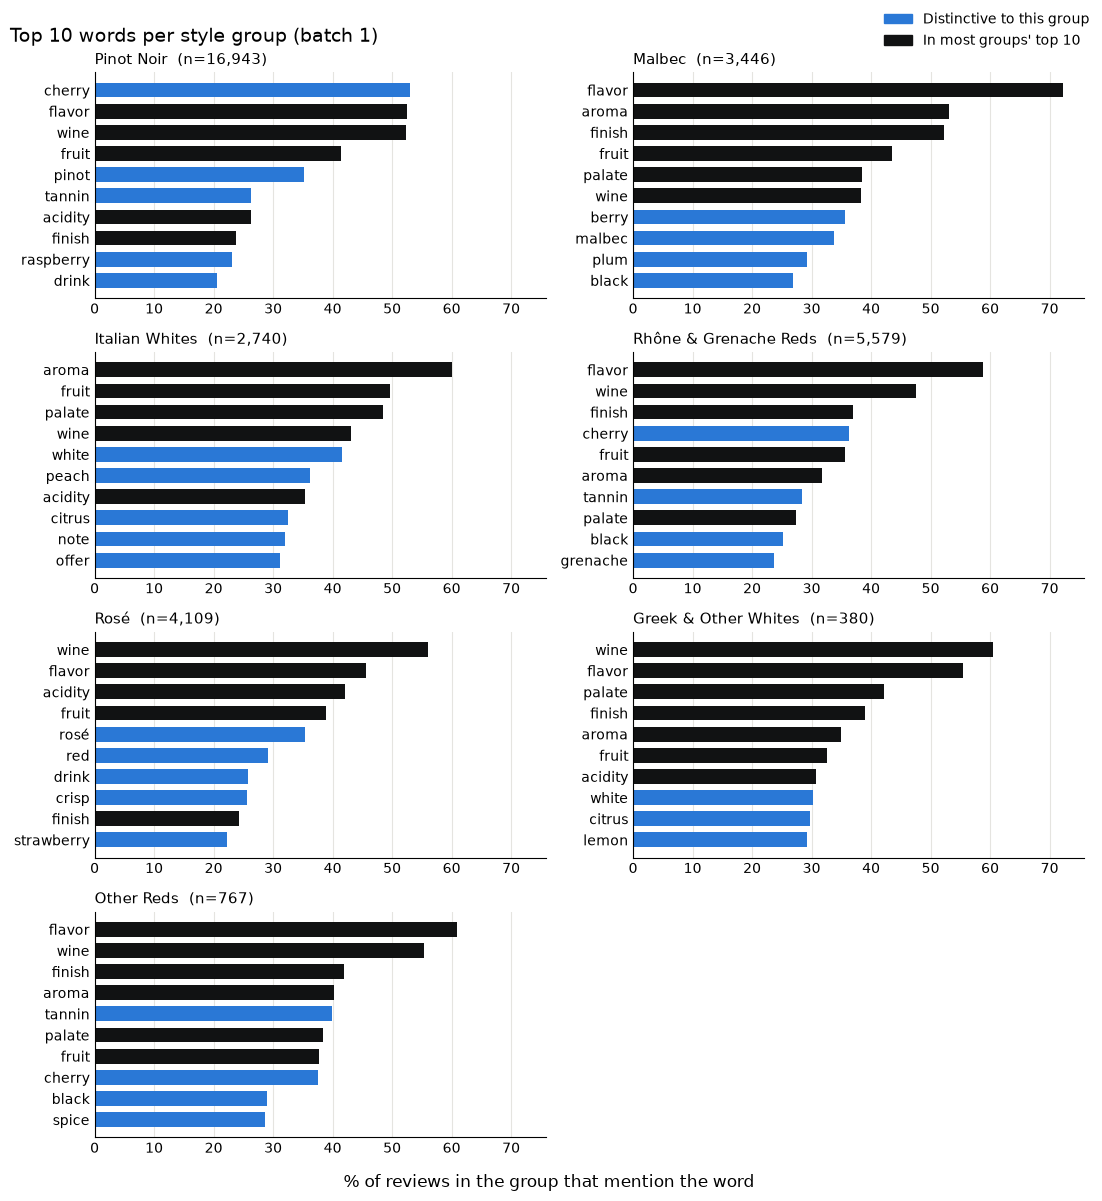

In [120]:
import math 
from matplotlib.patches import Patch

DISTINCT  =  "#2a78d6"  # Distinct will be blueeeee
SHARED = "#111213"  #  Shared will be redd

ncols = 2 
nrows = math.ceil(len(styles) / ncols) # fit to scalee... if more data anlaysis is needed
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3 * nrows), sharex=True) # size will also scale as well 
axes = axes.flatten()

for ax, style in zip(axes, styles):
    words, pcts = zip(*top_words[style]) 
    colors = [SHARED if w in shared else DISTINCT for w in words]

    ax.barh(words, pcts, color=colors, height=0.7)
    ax.invert_yaxis()
    ax.set_title(f"{style}  (n={group_size[style]:,})", loc="left", fontsize=11)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.xaxis.set_tick_params(labelbottom=True)

for ax in axes[len(styles):]: 
    ax.set_visible(False)

fig.legend(handles=[Patch(color=DISTINCT, label="Distinctive to this group"),
                    Patch(color=SHARED,   label="In most groups' top 10")],
           loc="upper right", frameon=False)
fig.suptitle(f"Top {TOP_N} words per style group (batch 1)", x=0.01, ha="left", fontsize=14)
fig.supxlabel("% of reviews in the group that mention the word")
plt.tight_layout()
plt.show()

# Notes
Steps moving forward, we can get rid of the top 10 common words that are shared between all of batch 1. In order to draw a distinction between the style groups of wine, its important to engineer features from each review text descritpion. 

List thus far: 

{"wine", "flavor", "aroma", "palate", "finish", "drink", "note", "show", "acidity"} 

Next step: apply these as stop words...

# Modifications and see similar words 

In [121]:
wine_words = {"wine", "flavor", "aroma", "palate", "finish", "drink", "note", "show", "acidity"}

keep = {"red", "white", "apple", "blend", "style", "other", "de", "di", "del", "la"}

# this will get rid of possible leakage
variety_words = set()
for varieties in batch1.values(): # grabbing the object list
    for name in varieties:
        for t in word_tokenize(name.lower()):
            if t.isalpha(): # checking again if they are just normal words
                variety_words.add(lemmantizer.lemmatize(t)) # adding the common words or the name of each wine variety into the lemmantizer list

variety_words = variety_words - keep # this is to ensure that words that don't really cause data leakage are still kept
print(len(variety_words), sorted(variety_words)[:40])

191 ['agiorgitiko', 'aidani', 'albana', 'albanello', 'alicante', 'and', 'ansonica', 'argaman', 'arneis', 'asprinio', 'assyrtico', 'assyrtiko', 'athiri', 'baco', 'biancale', 'bianco', 'biancolella', 'biancu', 'blanc', 'blauburgunder', 'bois', 'bombino', 'bouschet', 'boğazkere', 'cabernet', 'cannonau', 'caprettone', 'carignan', 'carignane', 'carignano', 'carineña', 'carnelian', 'carricante', 'catarratto', 'cayuga', 'chambourcin', 'chancellor', 'charbono', 'chardonel', 'chardonelle']


In [127]:
all_stops = stop_words | wine_words | variety_words # | this do be doing the join

def clean_token(text):
    tokens = word_tokenize(text.lower())
    tokens = [lemmantizer.lemmatize(t) for t in tokens if t.isalpha()] 
    return [t for t in tokens if t not in all_stops]

In [129]:
df_batch1["raw_tokens"] = df_batch1["tokens"]
df_batch1["tokens"] = df_batch1["description"].apply(clean_token)

In [ ]:
def own_name_rate(df, col):
    """ 
    This will measure what the % of each groups reviews mention one of the groups own variety word....
    """
    rates = {}
    for style, varieties in batch1.items():
        own = {lemmantizer.lemmatize(t) for v in varieties for t in word_tokenize(v.lower()) if t.isalpha()} - keep # current varieties and their name
        sub = df[df["style_group"] == style]

        # helsp us to see if there are words in both sets 
        hits = sub[col].apply(lambda toks: bool(own & set(toks)))  # & = words in both sets

        rates[style] = round(100 * hits.mean(), 1) # calculates the rate of styles that share words of their descripion with others. 
    return pd.Series(rates)

pd.DataFrame({"before_%": own_name_rate(df_batch1, "raw_tokens"),
              "after_%":  own_name_rate(df_batch1, "tokens")})        

,before_%,after_%
Pinot Noir,35.3,0.0
Rhône & Grenache Reds,44.6,0.0
Rosé,36.8,0.0
Malbec,33.7,0.0
Italian Whites,34.7,0.0
Other Reds,35.7,0.0
Greek & Other Whites,27.4,0.0


# Lets see the distinction now between each

In [ ]:
from collections import Counter

doc_freq = {}
group_size = {} 

for style in styles:
    sub = df_batch1[df_batch1["style_group"] == style]
    doc_freq["style"] = FreqDist(w for toks in sub["tokens"] for w in set(toks)) # grabbing frequency of each token within each style
    group_size[style] = len(sub) 

total_freq = Counter()
for fd in doc_freq.values():
    total_freq.update(fd) 
N = sum(group_size.values()) # grabbing the total number of reviews

In [137]:
"""
This is essentialy comparing every other word frequency from one style group to the others

PCT_GROUP: looks at how much the word token makes up out of all description

PCT_rest: compares that word % within that group to the rest of the other words 
"""
TOP_N = 10
distinct = {}

for style in styles:
    n = group_size[style] # grabs the review size of each style type
    rest_n = N - n # subtract how many from the total is subtracted

    rows = []
    for w, c in doc_freq[style].items():
        pct_group = 100 * c / n
        pct_rest = 100 * (total_freq[w] - c) / rest_n # subtracts the amount of items minus the count it had from the previous doc_frequency
        rows.append((w, pct_group, pct_rest, pct_group - pct_rest))

    distinct[style] = (pd.DataFrame(rows, columns=["word", "pct_group", "pct_rest", "diff"])
                         .nlargest(TOP_N, "diff"))

distinct["Rosé"] # taking a little peak

,word,pct_group,pct_rest,diff
18,crisp,25.626673,6.839725,18.786948
97,strawberry,22.170844,6.712443,15.458401
186,fruity,18.617669,4.736225,13.881443
24,red,29.082502,16.640429,12.442073
167,fresh,20.296909,9.653324,10.643585
54,light,20.102215,9.512644,10.589570
194,color,15.113166,4.598895,10.514272
131,ha,25.358968,15.732708,9.626260
268,pink,9.978097,0.549322,9.428775
31,bright,15.478219,7.027299,8.450920


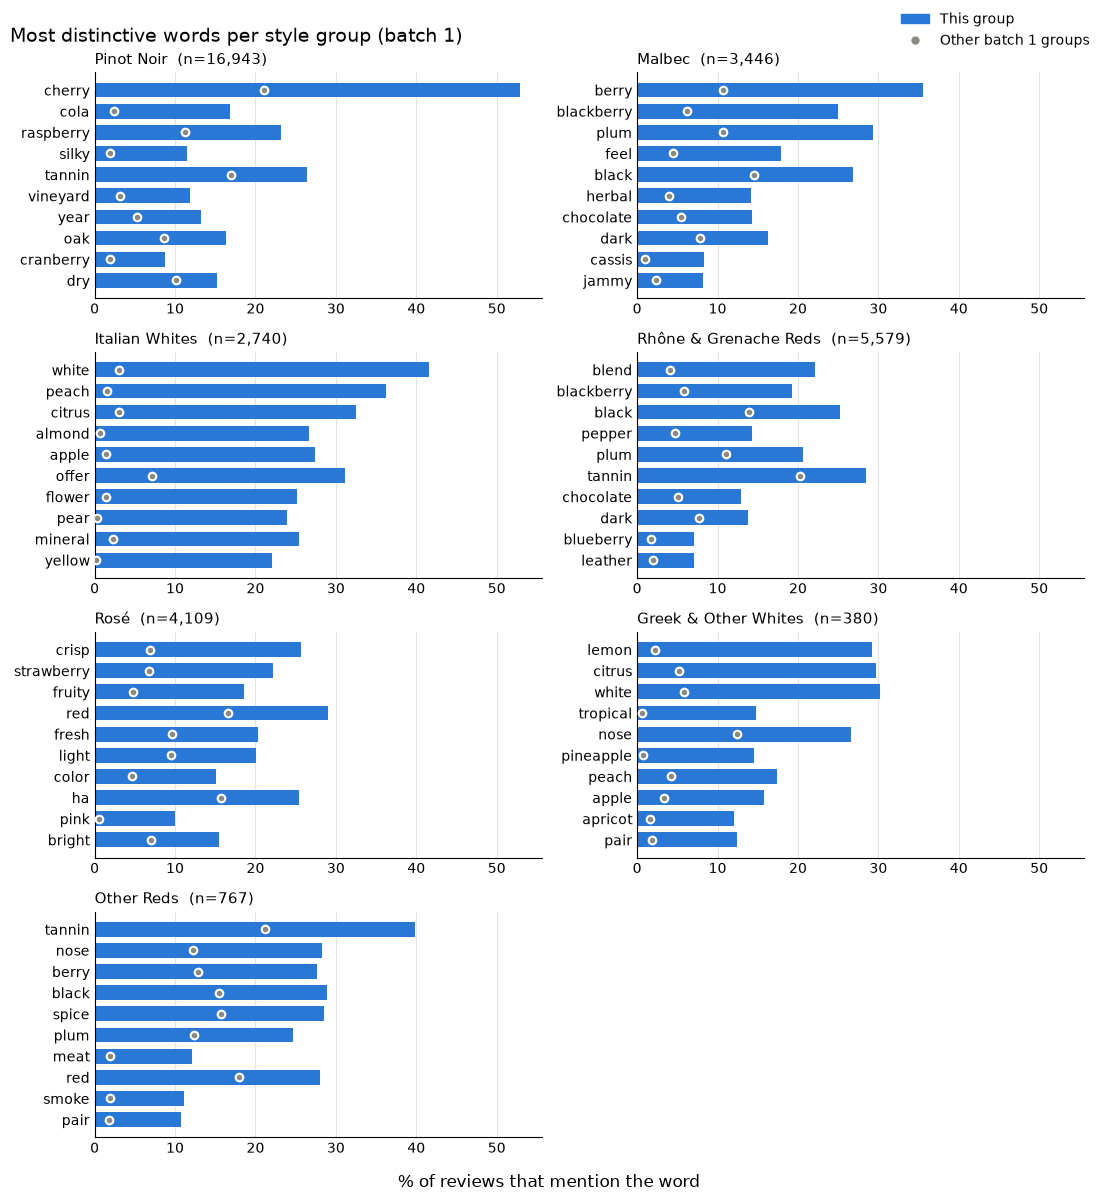

: 

In [ ]:
import math
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

GROUP = "#2a78d6"   # blue bar: this group
REST  = "#8a8984"   # gray dot: the other batch 1 groups

ncols = 2
nrows = math.ceil(len(styles) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3 * nrows), sharex=True)
axes = axes.flatten()

for ax, style in zip(axes, styles):
    d = distinct[style]

    ax.barh(d["word"], d["pct_group"], color=GROUP, height=0.7)
    ax.scatter(d["pct_rest"], d["word"], color=REST, s=30, zorder=3,
               edgecolor="white", linewidth=1.5) 
    ax.set_title(f"{style}  (n={group_size[style]:,})", loc="left", fontsize=11)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.xaxis.set_tick_params(labelbottom=True)

for ax in axes[len(styles):]:
    ax.set_visible(False)

fig.legend(handles=[Patch(color=GROUP, label="This group"),
                    Line2D([], [], marker="o", color="w", markerfacecolor=REST,
                           markersize=7, label="Other batch 1 groups")],
           loc="upper right", frameon=False)
fig.suptitle(f"Most distinctive words per style group (batch 1)", x=0.01, ha="left", fontsize=14)
fig.supxlabel("% of reviews that mention the word")
plt.tight_layout()
plt.show()


# Notes
After applying the neccessary modification using NLTK, we were able to filter out tokens of stop words that we believed to be shared across all style groups and any leakages that a tokenized word may have onto our model. As a result we can see that a large percent of tokenized words within each style group are unique that style group. 

**For example**: 
The top 10 words Pinot Noir are: Cherry, Cola, Raspberry, silky, etc. All of these words within each style group are unique or cover a high percentage of words that describe that particular style type. This is important because it will allow the model to weigh these words more in classifying which of these reviews describe a certain type of style group. 